# Research Site Locations

Alex Koiter

In [ ]:
suppressPackageStartupMessages({library(tidyverse)
library(ggspatial)
library(sf)
library(rnaturalearth)
library(ggrepel)
library(raster)
library(patchwork)
library(terra)
})

## Bounding box of region and sites

In [ ]:
box = c(xmin = 455200, ymin = 5616000, xmax = 466200, ymax = 5626500)

ag_site <- data.frame(x = c(464124, 463318),
                         y = c(5622932, 5622121)) %>% 
  st_as_sf(coords = c("x", "y"), crs = 3158) %>% 
  st_bbox() %>% 
  st_as_sfc()

forest_site <- data.frame(x = c(460822, 460189),
                         y = c(5619887, 5619206)) %>% 
  st_as_sf(coords = c("x", "y"), crs = 3158) %>% 
  st_bbox() %>% 
  st_as_sfc()

locations <- data.frame(name = c("Forest", "Agriculture"), 
                        long = c(-99.560041, -99.513808), 
                        lat = c( 50.726076,  50.752731)) %>%
  st_as_sf(coords = c("long", "lat"),  crs = 4326)

  #st_transform(crs = st_crs(land))

cities <- data.frame(name = "McCreary", long = -99.493, lat = 50.775) %>%
  st_as_sf(coords = c("long", "lat"),  crs = 4326) 

## Land use data of region

### Get data

In [ ]:
minnedosa_data <- "lcv_minnedosa_2004_2006_shp"
if (file.exists(minnedosa_data)) {
  print("The data already exists!")
} else {
  download.file("https://mli.gov.mb.ca/landuse/shp_zip_files/lcv_minnedosa_2004_2006_shp.zip", 
                destfile = "lcv_minnedosa_2004_2006_shp.zip")
  unzip("lcv_minnedosa_2004_2006_shp.zip", exdir = "lcv_minnedosa_2004_2006_shp")
}

[1] "The data already exists!"

### Summarize and crop

In [ ]:
land <- st_read(here::here("./notebooks/lcv_minnedosa_2004_2006_shp/lcv_minnedosa_2004_2006.shp")) %>%
  st_crop(st_bbox(box)) %>%
  st_transform(4269) %>%
  mutate(Land_use = recode(CLASSNAME, "Agricultural Field" = "Agriculture", "Agri - Forage Field" = "Agriculture", "Water Body" = "Water", "Wetland - Treed Bog" = "Wetland", "Wetland - Marsh" = "Wetland", "Decidious Forest" = "Forest", "Open Decidious Forest" = "Forest", "Mixedwood Forest" = "Forest", "Forest Cut Blocks" = "Forest", "Coniferous Forest" = "Forest","Roads Trails Rail Lines" = "Other", "Sand and Gravel" = "Other", "Cultural Features" = "Other", "Range and Grassland" = "Forage")) %>%
  st_make_valid() %>%
  st_simplify(dTolerance = 0.0001, preserveTopology = F) %>%
  group_by(Land_use) %>%
  summarise(do_union = TRUE) %>%
  mutate(Land_use = factor(Land_use, levels=c("Agriculture", "Forest", "Forage", "Water", "Wetland", "Other")))

Reading layer `lcv_minnedosa_2004_2006' from data source 
  `/home/alex/Dropbox/terrain-attributes/notebooks/lcv_minnedosa_2004_2006_shp/lcv_minnedosa_2004_2006.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 160653 features and 5 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: 429972 ymin: 5542070 xmax: 549972 ymax: 5656880
Projected CRS: UTM

all geometries

Warning in st_simplify.sfc(st_geometry(x), preserveTopology, dTolerance):
argument preserveTopology cannot be set to FALSE when working with ellipsoidal
coordinates since the algorithm behind st_simplify always preserves topological
relationships

## DEM data

Freely available from <https://maps.canada.ca/czs/index-en.html> Data type is Elevation. You provide the clipping area and then submit the data request

In [ ]:
topo <- raster::aggregate(raster(here::here("./notebooks/DEM.tif")), fact = 3) %>%
  crop(extent(land)) %>%
  as.data.frame(xy = T)

## Hydro data

Freely available from <https://maps.canada.ca/czs/index-en.html> Data type is the CanVec. You provide the clipping area and then submit the data request

In [ ]:
water_linear <- st_read(here::here("./notebooks/canvec_190514_89905/water_linear_flow_1.shp")) %>%
  st_transform(crs = st_crs(land)) %>%
  st_make_valid() %>%
  st_crop(st_bbox(land))

Reading layer `water_linear_flow_1' from data source 
  `/home/alex/Dropbox/terrain-attributes/notebooks/canvec_190514_89905/water_linear_flow_1.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 5160 features and 44 fields
Geometry type: LINESTRING
Dimension:     XY
Bounding box:  xmin: -99.9082 ymin: 50.54151 xmax: -99.12695 ymax: 51.16603
Geodetic CRS:  NAD83(CSRS)

all geometries

## Canada wide map

In [ ]:
canada <- ne_states(country = "Canada", returnclass = "sf") %>%
  st_transform(crs = 3348)

locations2 <- data.frame(name = c("Center"), long = c(-99.989671), lat = c(50.742554)) %>%
  st_as_sf(coords = c("long", "lat"),  crs = 4326) %>%
  st_transform(crs = st_crs(land))

## Maps

### Canada

In [ ]:
p1 <- ggplot() +
  theme_bw() +
  layer_spatial(canada, fill = "white") +
  layer_spatial(locations2, shape = 23, colour = "red", fill = "red", size = 2) +
  annotation_scale(location = "bl",
                   height = unit(0.05, "cm")) +
  annotation_north_arrow(location = "br", 
                         height = unit(0.5, "cm"),
                         width = unit(0.5, "cm")) +
  theme(axis.text = element_blank(),
        axis.ticks = element_blank(),
        axis.title = element_blank(),
        plot.margin = unit(c(0,0,0,0), "mm"))

### Land use

In [ ]:
p2 <- ggplot() +
  theme_bw(base_size = 10) +
  geom_sf(data = land, aes(fill = Land_use)) +
  scale_fill_manual(values=c("#458B00", "#006400", "#CDAD00", "#009ACD", "#CDB38B",  "#C1CDCD"), name = "Land use") +
  geom_sf(data = water_linear, colour = "#009ACD", lwd = 0.5) +
  geom_label_repel(
    data = head(locations),
    aes(label = name, geometry = geometry),
    stat = "sf_coordinates",
    min.segment.length = 0,
    nudge_y = 0.01, 
    size = 3) +
  geom_label_repel(
    data = head(locations),
    aes(label = name, geometry = geometry),
    stat = "sf_coordinates",
    min.segment.length = 0,
    nudge_y = 0.01, 
    size = 3) +
  geom_sf(data = ag_site, fill = NA, colour = "red", lwd = 1) +
  geom_sf(data = forest_site, fill = NA, colour = "red", lwd = 1) +
  geom_label_repel(
    data = head(cities),
    aes(label = name, geometry = geometry),
    stat = "sf_coordinates",
    min.segment.length = 0,
    nudge_y = 0.01,
    size = 2) +
  annotation_scale(location = "bl",
                   height = unit(0.05, "cm")) +
  annotation_north_arrow(location = "br", 
                         height = unit(0.5, "cm"),
                         width = unit(0.5, "cm")) +
  theme(axis.text = element_blank(),
        axis.ticks = element_blank(),
        axis.title = element_blank(),
        plot.margin = unit(c(0,0,0,0), "mm"),
        legend.position = "bottom",
        legend.title = element_blank(),
        legend.key.size = unit(5, 'mm'),
        legend.box.spacing = unit(0, "pt")) +
  scale_x_continuous(expand = c(0,0)) +
  scale_y_continuous(expand = c(0,0))

### DEM

In [ ]:
p3 <- ggplot() +
  theme_bw(base_size = 10) +
  geom_raster(data = topo , aes(x = x, y = y, fill = DEM)) + 
  scale_fill_viridis_c(name = "Elev. (m)  ", limits = c(282, 800), breaks = c(300, 550, 800)) +
  geom_label_repel(
    data = head(locations),
    aes(label = name, geometry = geometry),
    stat = "sf_coordinates",
    min.segment.length = 0,
    nudge_y = 0.01,
    size = 3) +
  geom_sf(data = ag_site, fill = NA, colour = "red", lwd = 1) +
  geom_sf(data = forest_site, fill = NA, colour = "red", lwd = 1) +
  geom_label_repel(
    data = head(cities),
    aes(label = name, geometry = geometry),
    stat = "sf_coordinates",
    min.segment.length = 0,
    nudge_y = 0.01,
    size = 3) +
  scale_x_continuous(expand = c(0,0)) +
  scale_y_continuous(expand = c(0,0)) +
  annotation_scale(location = "bl",
                   height = unit(0.05, "cm")) +
  annotation_north_arrow(location = "br", 
                         height = unit(0.5, "cm"),
                         width = unit(0.5, "cm")) +
  theme(axis.text = element_blank(),
        axis.ticks = element_blank(),
        axis.title = element_blank(),
        plot.margin = unit(c(0,0,0,0), "mm"),
        legend.position = "bottom",
        legend.box.spacing = unit(0, "pt")) 

In [ ]:
coords <- read_csv(here::here("./notebooks/coords.csv"), show_col_types = FALSE) %>% 
  st_as_sf(coords = c("long", "lat"),  crs = 4326) %>%
  st_transform(crs = 26914)

In [ ]:
ag_topo <- read_csv(here::here("./notebooks/ag_terrain_data.csv"), show_col_types = FALSE) %>%
  dplyr::select("x", "y", "elevation")
ag_topo <- rast(ag_topo)
crs(x = ag_topo, warn=FALSE) <- "epsg:26914"

# p4 <- ggplot() +
#   tidyterra::geom_spatraster(data = ag_topo, aes(fill = elevation)) +
#   scale_fill_viridis_c(name = "Elev. (m)", option = "viridis", limits = c(309, 312), breaks = seq(309, 312, 1)) +
#   geom_sf(data = filter(coords, site == "Agriculture"), size =1) +
#   theme_bw(base_size = 10) +
# theme(axis.text = element_blank(),
#         axis.ticks = element_blank(),
#         axis.title = element_blank(),
#         plot.margin = unit(c(0,0,0,0), "mm"),
#         legend.position = "bottom",
#         legend.box.spacing = unit(0, "pt")) +
#   scale_y_continuous(expand = c(0,0)) +
#   scale_x_continuous(expand = c(0,0)) +
#   annotation_scale(location = "bl",
#                    height = unit(0.05, "cm")) +
#   annotation_north_arrow(location = "br", 
#                          height = unit(0.5, "cm"),
#                          width = unit(0.5, "cm"))

p4 <- ggplot() +
  tidyterra::geom_spatraster(data = ag_topo, aes(fill = elevation)) +
  scale_fill_viridis_c(
    name   = "Elev. (m)",
    option = "viridis",
    limits = c(309, 312),
    breaks = seq(309, 312, 1)
  ) +
  geom_sf(
    data  = dplyr::filter(coords, site == "Agriculture"),
    aes(shape = "Sampling location"),
    size = 1, color = "black", fill = "black", stroke = 0.5
  ) +
  scale_shape_manual(
    name   = NULL,
    values = c("Sampling location" = 21)
  ) +
  guides(
    shape = guide_legend(
      order = 1,
      override.aes = list(size = 1, fill = "black", color = "black")
    ),
    fill  = guide_colorbar(order = 2)
  ) +
  annotation_scale(location = "bl", height = unit(0.05, "cm")) +
  annotation_north_arrow(
    location = "br",
    height   = unit(0.5, "cm"),
    width    = unit(0.5, "cm")
  ) +
  theme_bw(base_size = 10) +
  theme(
    axis.text    = element_blank(),
    axis.ticks   = element_blank(),
    axis.title   = element_blank(),
    legend.position    = "bottom",
    legend.box.spacing = unit(0, "pt"),
    legend.box         = "vertical",
    legend.spacing.x   = unit(6, "pt"),
  ) +
  scale_y_continuous(expand = c(0, 0)) +
  scale_x_continuous(expand = c(0, 0))

In [ ]:
forest_topo <- read_csv(here::here("./notebooks/forest_terrain_data.csv"), show_col_types = FALSE) %>%
  dplyr::select("x", "y", "elevation")
forest_topo <- rast(forest_topo)
crs(x = forest_topo, warn=FALSE) <- "epsg:26914"

# p5 <- ggplot() +
#   tidyterra::geom_spatraster(data = forest_topo, aes(fill = elevation)) +
#   scale_fill_viridis_c(name = "Elev. (m)", option = "viridis") +
#   geom_sf(data = filter(coords, site == "Forest"), size =1) +
#   theme_bw(base_size = 10) +
# theme(axis.text = element_blank(),
#         axis.ticks = element_blank(),
#         axis.title = element_blank(),
#         plot.margin = unit(c(0,0,0,0), "mm"),
#         legend.position = "bottom",
#         legend.box.spacing = unit(0, "pt")) +
#   scale_y_continuous(expand = c(0,0)) +
#   scale_x_continuous(expand = c(0,0)) +
#   annotation_scale(location = "bl",
#                    height = unit(0.05, "cm")) +
#   annotation_north_arrow(location = "br", 
#                          height = unit(0.5, "cm"),
#                          width = unit(0.5, "cm"))


p5 <- ggplot() +
  tidyterra::geom_spatraster(data = forest_topo, aes(fill = elevation)) +
  scale_fill_viridis_c(
    name   = "Elev. (m)",
    option = "viridis",
    breaks = seq(360, 375, 5)
  ) +
  geom_sf(
    data  = dplyr::filter(coords, site == "Forest"),
    aes(shape = "Sampling location"),
    size = 1, color = "black", fill = "black", stroke = 0.5
  ) +
  scale_shape_manual(
    name   = NULL,
    values = c("Sampling location" = 21)
  ) +
  guides(
    shape = guide_legend(
      order = 1,
      override.aes = list(size = 1, fill = "black", color = "black")
    ),
    fill  = guide_colorbar(order = 2)
  ) +
  annotation_scale(location = "bl", height = unit(0.05, "cm")) +
  annotation_north_arrow(
    location = "br",
    height   = unit(0.5, "cm"),
    width    = unit(0.5, "cm")
  ) +
  theme_bw(base_size = 10) +
  theme(
    axis.text    = element_blank(),
    axis.ticks   = element_blank(),
    axis.title   = element_blank(),
    legend.position    = "bottom",
    legend.box.spacing = unit(0, "pt"),
    legend.box         = "vertical",
    legend.spacing.x   = unit(6, "pt"),
  ) +
  scale_y_continuous(expand = c(0, 0)) +
  scale_x_continuous(expand = c(0, 0))

Warning in st_point_on_surface.sfc(sf::st_zm(x)): st_point_on_surface may not
give correct results for longitude/latitude data
Warning in st_point_on_surface.sfc(sf::st_zm(x)): st_point_on_surface may not
give correct results for longitude/latitude data
Warning in st_point_on_surface.sfc(sf::st_zm(x)): st_point_on_surface may not
give correct results for longitude/latitude data

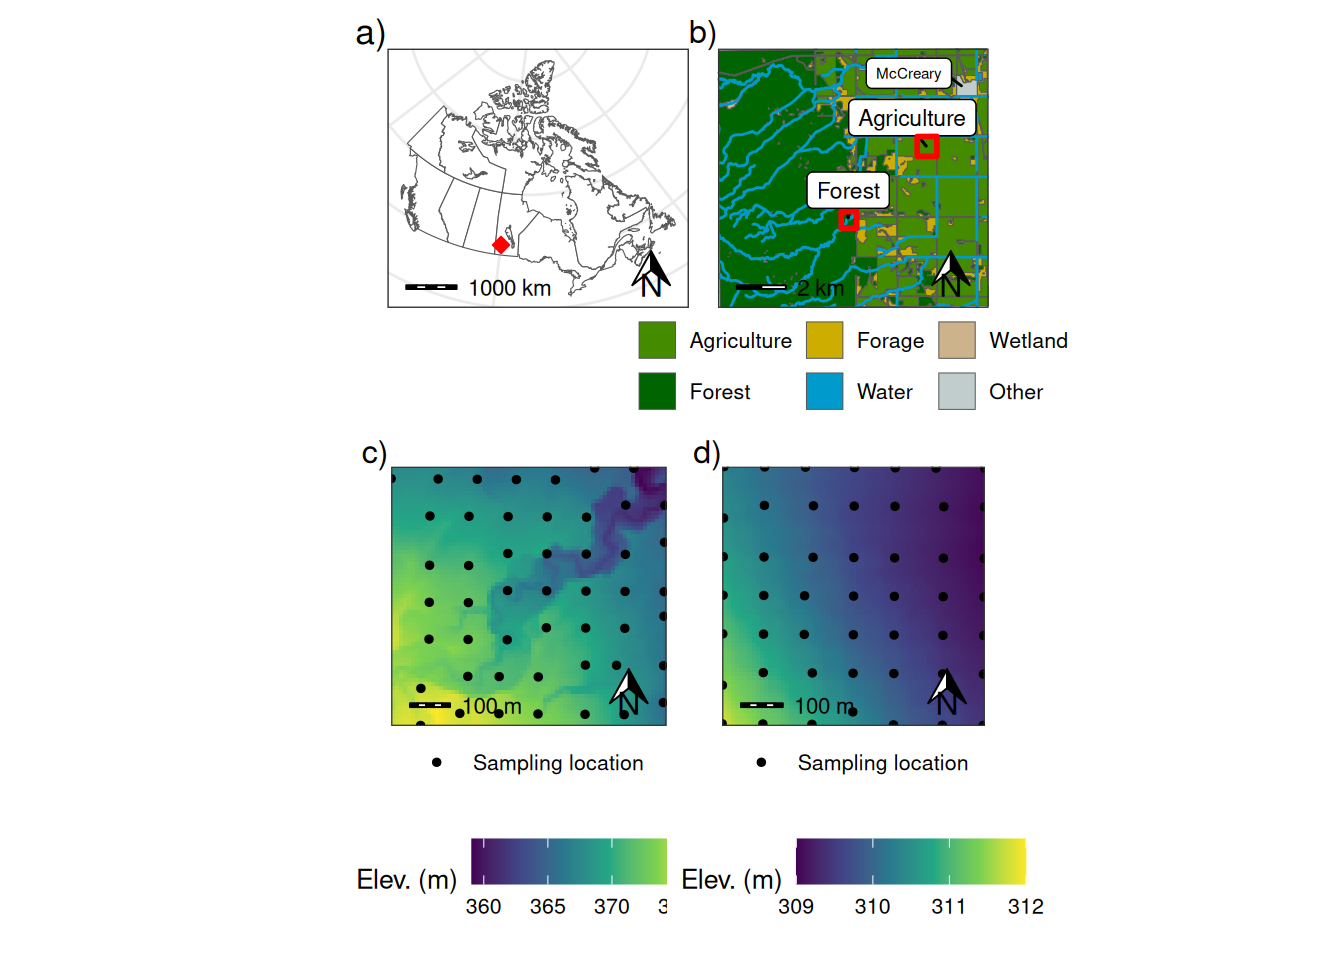

In [ ]:
#| label: fig-location_map
#| fig-cap: a) Map showing the location of the study sites within Canada. b) Location of the two study sites and nearby town of McCreary and regionalland use. Local topography and soil sampling locations at the c) forested site and d) agricultural site at a spacing of approximately 100m.

# p6 <- p1 + guide_area() + p2 + p3 + plot_layout(guides = "collect") + plot_annotation(tag_levels = 'a', tag_suffix = ')')
# 
# 
# p7 <- p5 + p4 
# 
# 
# p6/p7 + plot_annotation(tag_levels = 'a', tag_suffix = ')')
# 
# p6 / (p7)

  
# p8 <- p1 + plot_spacer() + p2 +p3+ p5 + p4 + plot_layout(ncol = 2) + plot_annotation(tag_levels = 'a', tag_suffix = ')')
# p8

# p8 <- p1  + p2 +p3+ p5 + p4 + plot_spacer() + plot_layout(ncol = 3, heights = c(1, 1)) + plot_annotation(tag_levels = 'a', tag_suffix = ')')
# p8


p8 <- (p1  + p2)/ (p5 + p4) + plot_annotation(tag_levels = 'a', tag_suffix = ')')
p8